# **Project Heimdall: Southeast Asian Agri-Drought Trend Detective & Super El Niño Early Warning Dashboard**

A NASA Space Apps-inspired geospatial time-series dashboard linking historical climate trends to predictive agricultural risks across the Southeast Asia.

In [3]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import requests
import io
import seaborn as sns

To evaluate the 3-year climate trajectory (2023–2026) across Southeast Asia and the Philippines, the following hypotheses were established:

Hypothesis 1 (Trend Analysis - Null vs. Alternative):
Null Hypothesis ($H_0$): There is no significant monotonic trend or linear rate of change in precipitation, soil moisture, and surface temperature over specific period.

Alternative Hypothesis ($H_a$): There is a statistically significant long-term climatic shift, characterized by decreasing precipitation and soil moisture alongside increasing surface temperatures.

In [4]:
!pip install xarray netcdf4 matplotlib

Total CSV files detected: 3

Processing file: g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_Rainf_f_tavg.20230101-20261030.30E_21N_100E_56N.csv


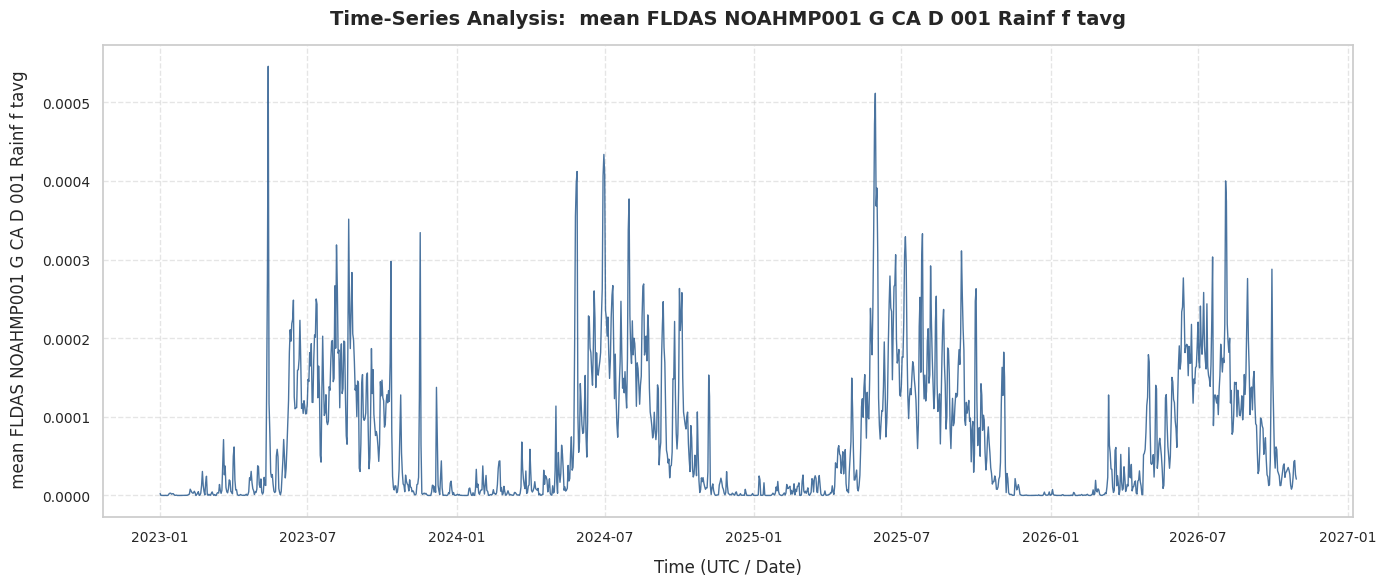


Processing file: g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_SoilMoi00_10cm_tavg.20230101-20261030.30E_21N_100E_56N.csv


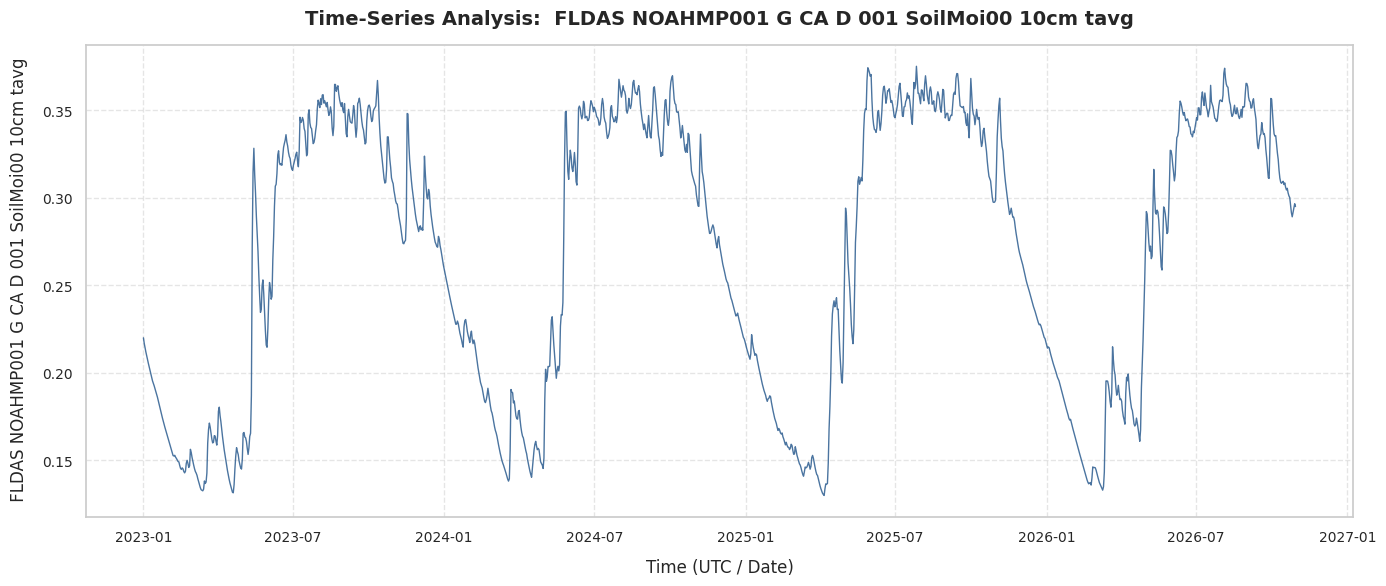


Processing file: g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_Tair_f_tavg.20230101-20261030.30E_21N_100E_56N.csv


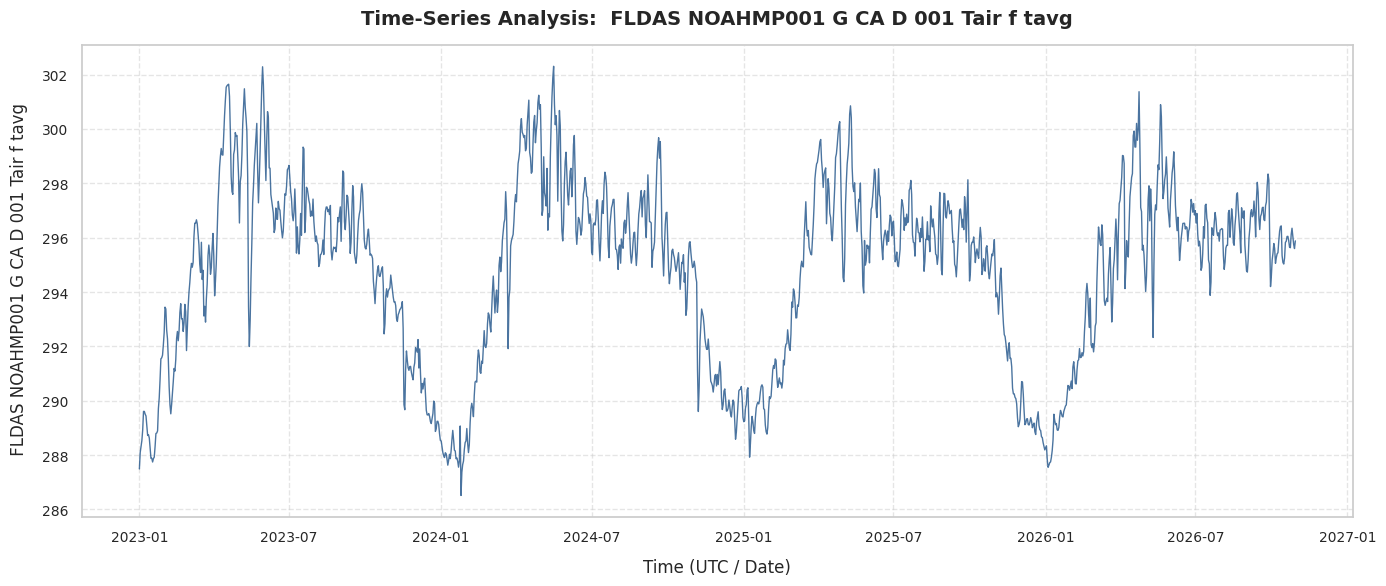

In [5]:
import glob
import seaborn as sns

# Configure visual styling for formal and publication-ready plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

# 1. Automatically retrieve all CSV files matching the Giovanni time-series naming convention
csv_files = sorted(glob.glob("g4.areaAvgTimeSeries.*.csv"))

print(f"Total CSV files detected: {len(csv_files)}")

# 2. Iterate through each file to process and visualize the data
for file_path in csv_files:
    print(f"\nProcessing file: {file_path}")

    try:
        # Read the CSV file while skipping metadata header rows (Giovanni format typically uses skiprows=8)
        df = pd.read_csv(file_path, skiprows=8)

        # Verify columns exist
        if df.shape[1] < 2:
            print(f"Skipping {file_path}: Insufficient columns found.")
            continue

        time_col = df.columns[0]   # Typically represents 'Time' or 'Date'
        value_col = df.columns[1]  # Represents the specific climate/environmental variable

        # Clean and parse the datetime column, coercing parsing errors to NaT
        df[time_col] = pd.to_datetime(df[time_col], errors='coerce')

        # Drop rows with missing dates or values to ensure data integrity
        df = df.dropna(subset=[time_col, value_col])

        # 3. Generate formal time-series line plot
        fig, ax = plt.subplots(figsize=(14, 6))

        ax.plot(
            df[time_col],
            df[value_col],
            color='#2b5c8f',
            linewidth=1.0,
            alpha=0.85,
            label='Area-Averaged Value'
        )

        # Format plot titles and axis labels professionally
        clean_title = value_col.replace('_', ' ')
        ax.set_title(f"Time-Series Analysis: {clean_title}", fontweight='bold', pad=15)
        ax.set_xlabel("Time (UTC / Date)", labelpad=10)
        ax.set_ylabel(clean_title, labelpad=10)

        # Enable grid lines for enhanced readability
        ax.grid(True, linestyle='--', alpha=0.5)

        # Adjust layout spacing and render the visualization
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"An error occurred while processing {file_path}: {e}")

Total NetCDF files detected: 3

Processing NetCDF file: g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_Rainf_f_tavg.20230101-20261030.30E_21N_100E_56N.nc


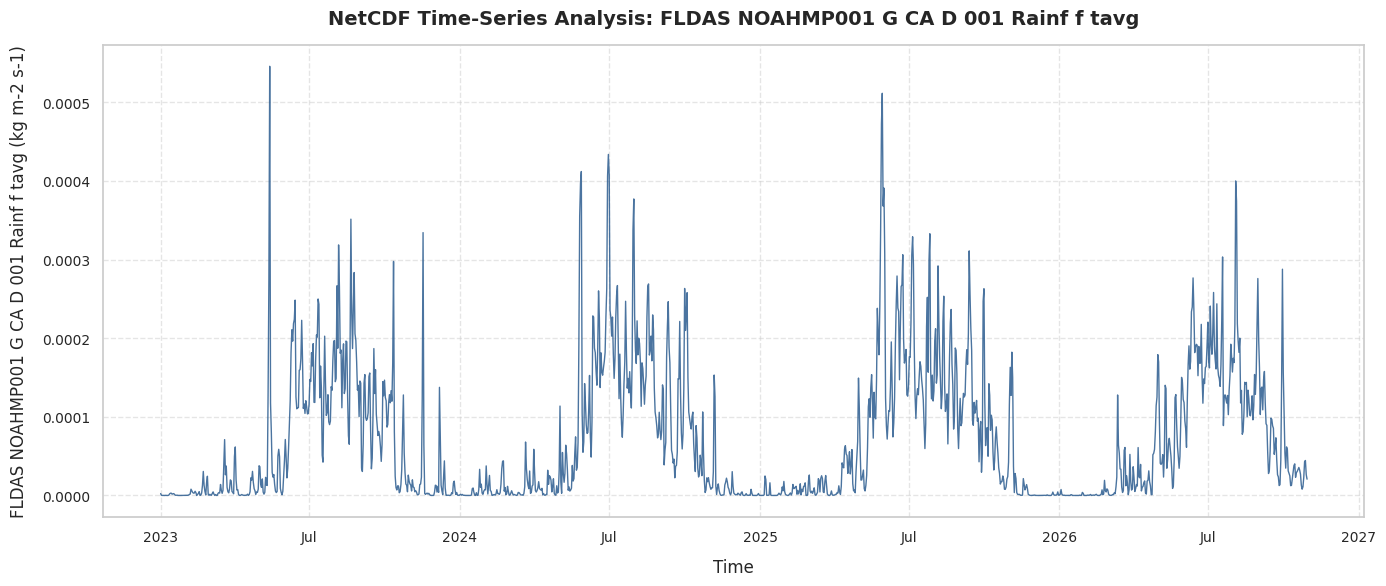


Processing NetCDF file: g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_SoilMoi00_10cm_tavg.20230101-20261030.30E_21N_100E_56N.nc


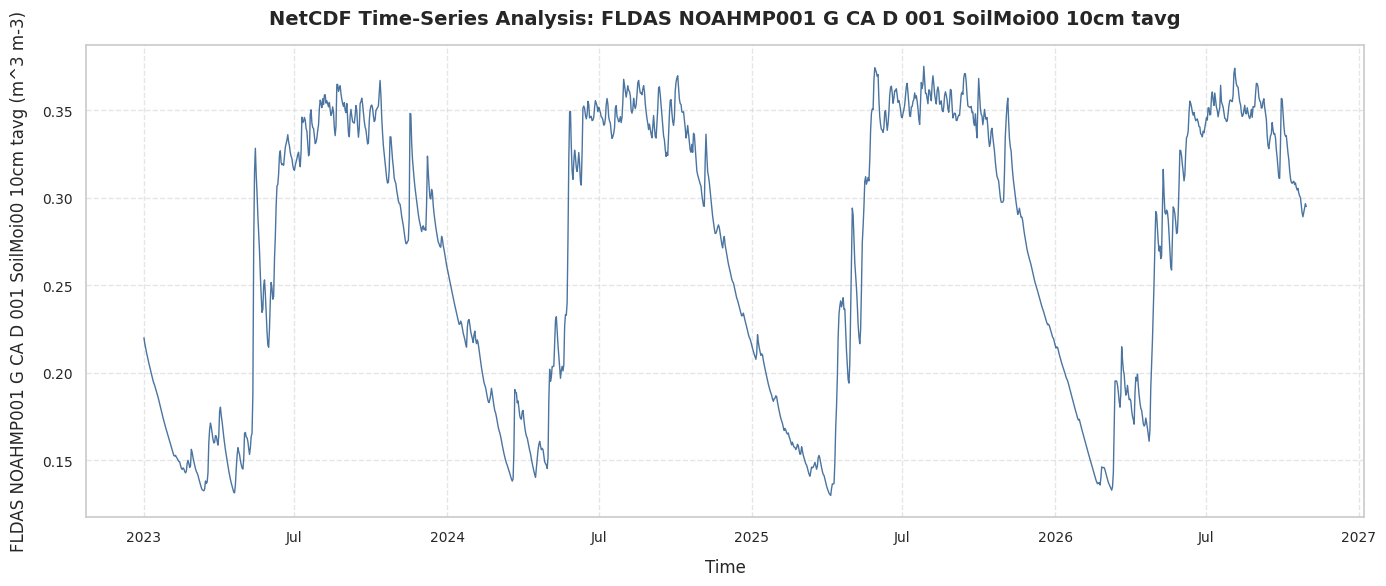


Processing NetCDF file: g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_Tair_f_tavg.20230101-20261030.30E_21N_100E_56N.nc


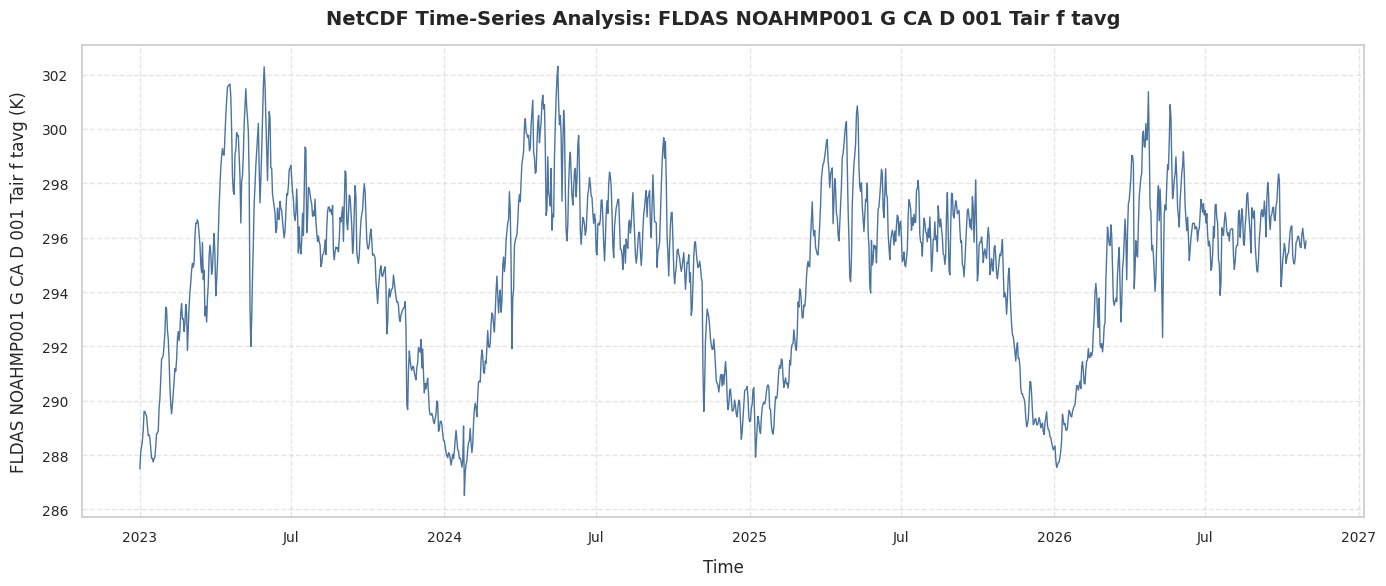

In [6]:
import xarray as xr
# Configure visual styling for formal and publication-ready plots
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

# 1. Automatically retrieve all NetCDF (.nc) files in the directory matching the pattern
nc_files = sorted(glob.glob("g4.areaAvgTimeSeries.*.nc"))

print(f"Total NetCDF files detected: {len(nc_files)}")

# 2. Iterate through each NetCDF file to process and visualize
for file_path in nc_files:
    print(f"\nProcessing NetCDF file: {file_path}")

    try:
        # Open the NetCDF dataset using xarray
        ds = xr.open_dataset(file_path)

        # Identify data variables present in the dataset (excluding coordinates/dimensions)
        data_vars = list(ds.data_vars)

        if not data_vars:
            print(f"No data variables found in {file_path}. Skipping.")
            ds.close()
            continue

        # Select the primary data variable (usually the first data variable in Giovanni NetCDF outputs)
        var_name = data_vars[0]
        da = ds[var_name]

        # 3. Generate time-series or spatial visualization depending on dimensions
        fig, ax = plt.subplots(figsize=(14, 6))

        # If the data has a 'time' dimension, plot as a time series
        if 'time' in da.dims:
            # If spatial dimensions (lat/lon) exist, compute spatial mean to get a 1D time series
            spatial_dims = [dim for dim in ['lat', 'lon', 'latitude', 'longitude'] if dim in da.dims]
            if spatial_dims:
                da_plottable = da.mean(dim=spatial_dims, skipna=True)
            else:
                da_plottable = da

            da_plottable.plot(ax=ax, color='#2b5c8f', linewidth=1.0, alpha=0.85)

            clean_title = var_name.replace('_', ' ')
            ax.set_title(f"NetCDF Time-Series Analysis: {clean_title}", fontweight='bold', pad=15)
            ax.set_xlabel("Time", labelpad=10)
            ax.set_ylabel(f"{clean_title} ({da.attrs.get('units', '')})", labelpad=10)
            ax.grid(True, linestyle='--', alpha=0.5)

        else:
            # Fallback for 2D spatial maps if time dimension is absent
            da.plot(ax=ax, cmap='YlGnBu')
            ax.set_title(f"Spatial Map: {var_name}", fontweight='bold', pad=15)

        plt.tight_layout()
        plt.show()

        # Close the dataset properly after processing
        ds.close()

    except Exception as e:
        print(f"An error occurred while processing {file_path}: {e}")

In [7]:

# 1. Retrieve all CSV files in the directory
csv_files = sorted(glob.glob("g4.areaAvgTimeSeries.*.csv"))

print("=" * 70)
print("STATISTICAL ANALYSIS SUMMARY REPORT")
print("=" * 70)

# 2. Loop through each CSV and compute key statistical metrics
for file_path in csv_files:
    try:
        # Read Giovanni CSV format (skipping metadata header rows)
        df = pd.read_csv(file_path, skiprows=8)

        if df.shape[1] < 2:
            continue

        time_col = df.columns[0]
        val_col = df.columns[1]

        # Clean data and ensure numeric values
        df[time_col] = pd.to_datetime(df[time_col], errors='coerce')
        df[val_col] = pd.to_numeric(df[val_col], errors='coerce')
        df = df.dropna(subset=[time_col, val_col])

        # Compute statistical parameters
        mean_val = df[val_col].mean()
        median_val = df[val_col].median()
        std_val = df[val_col].std()
        min_val = df[val_col].min()
        max_val = df[val_col].max()

        # Print structured summary for each variable
        print(f"\nVariable: {val_col}")
        print(f"----------------------------------------------------------------------")
        print(f"  • Total Records (n) : {len(df)}")
        print(f"  • Mean              : {mean_val:.4f}")
        print(f"  • Median            : {median_val:.4f}")
        print(f"  • Standard Deviation: {std_val:.4f}")
        print(f"  • Minimum Value     : {min_val:.4f} (Recorded on: {df.loc[df[val_col].idxmin(), time_col].strftime('%Y-%m-%d')})")
        print(f"  • Maximum Value     : {max_val:.4f} (Recorded on: {df.loc[df[val_col].idxmax(), time_col].strftime('%Y-%m-%d')})")

    except Exception as e:
        print(f"Error processing {file_path}: {e}")

print("\n" + "=" * 70)
print("Analysis complete.")

STATISTICAL ANALYSIS SUMMARY REPORT

Variable:  mean_FLDAS_NOAHMP001_G_CA_D_001_Rainf_f_tavg
----------------------------------------------------------------------
  • Total Records (n) : 1399
  • Mean              : 0.0001
  • Median            : 0.0000
  • Standard Deviation: 0.0001
  • Minimum Value     : 0.0000 (Recorded on: 2023-01-05)
  • Maximum Value     : 0.0005 (Recorded on: 2023-05-14)

Variable:  FLDAS_NOAHMP001_G_CA_D_001_SoilMoi00_10cm_tavg
----------------------------------------------------------------------
  • Total Records (n) : 1399
  • Mean              : 0.2684
  • Median            : 0.2906
  • Standard Deviation: 0.0792
  • Minimum Value     : 0.1298 (Recorded on: 2025-04-06)
  • Maximum Value     : 0.3750 (Recorded on: 2025-07-27)

Variable:  FLDAS_NOAHMP001_G_CA_D_001_Tair_f_tavg
----------------------------------------------------------------------
  • Total Records (n) : 1399
  • Mean              : 294.8113
  • Median            : 295.6508
  • Standard Devi

In [8]:

# 1. Automatically retrieve all 3 CSV files in the directory
files = sorted(glob.glob("g4.areaAvgTimeSeries.*.csv"))
dfs_monthly = []

for f in files:
    temp_df = pd.read_csv(f, skiprows=8)
    time_col = temp_df.columns[0]
    val_col = temp_df.columns[1]

    temp_df[time_col] = pd.to_datetime(temp_df[time_col], errors='coerce')
    temp_df = temp_df.dropna(subset=[time_col])
    temp_df.set_index(time_col, inplace=True)

    # Assign clean variable names based on the 3 active files
    if 'Tair' in f:
        col_name = 'Air_Temp'
    elif 'Rainf' in f:
        col_name = 'Rainfall'
    elif 'SoilMoi00_10cm' in f:
        col_name = 'Soil_Moi_0_10cm'
    else:
        col_name = 'Value'

    # Resample daily data to Monthly Mean for synchronized comparison
    monthly_series = temp_df[val_col].resample('MS').mean()
    dfs_monthly.append(monthly_series.rename(col_name))

# Merge all files into a single master dataframe
df_merged = pd.concat(dfs_monthly, axis=1).reset_index()
df_merged = df_merged.rename(columns={df_merged.columns[0]: 'Date'})

# Filter strictly for the available date range (2023 to Oct 2026)
mask = (df_merged['Date'] >= '2023-01-01') & (df_merged['Date'] <= '2026-10-30')
df_final = df_merged.loc[mask].dropna().copy()

print("=" * 70)
print(f"FORMAL STATISTICAL ANALYSIS REPORT (2023–2026)")
print(f"Total Aligned Months (n) = {len(df_final)}")
print("=" * 70)

# 2. Pearson Correlation Matrix (r)
vars_to_analyze = ['Air_Temp', 'Rainfall', 'Soil_Moi_0_10cm']
corr_matrix = df_final[vars_to_analyze].corr()

print("\n[1] PEARSON CORRELATION MATRIX (r):")
print("-" * 50)
print(corr_matrix.round(4))

# 3. OLS Regression (Parametric Rate of Change & p-values)
print("\n[2] OLS REGRESSION (Parametric Trend & Slope):")
print("-" * 50)
for col in vars_to_analyze:
    x = np.arange(len(df_final))
    y = df_final[col].values
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    print(f"  • Variable: {col}")
    print(f"    - Monthly Rate of Change (Slope): {slope:.6f}")
    print(f"    - R-squared ($R^2$): {r_value**2:.4f}")
    print(f"    - p-value: {p_value:.4e} {'(Statistically Significant)' if p_value < 0.05 else ''}")

# 4. Mann-Kendall Trend Test (Non-Parametric)
try:
    import pymannkendall as mk
    has_mk = True
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "pymannkendall"], check=True)
    import pymannkendall as mk
    has_mk = True

print("\n[3] MANN-KENDALL TREND TEST (Non-Parametric Monotonic Trend):")
print("-" * 50)
for col in vars_to_analyze:
    result = mk.original_test(df_final[col].values)
    print(f"  • Variable: {col}")
    print(f"    - Trend: {result.trend}")
    print(f"    - Z-statistic: {result.z:.4f}")
    print(f"    - p-value: {result.p:.4e}")
    print(f"    - Sen's Slope (Median Rate of Change): {result.slope:.6f}")

print("\n" + "=" * 70)
print("Statistical analysis completed successfully.")

FORMAL STATISTICAL ANALYSIS REPORT (2023–2026)
Total Aligned Months (n) = 46

[1] PEARSON CORRELATION MATRIX (r):
--------------------------------------------------
                 Air_Temp  Rainfall  Soil_Moi_0_10cm
Air_Temp           1.0000    0.5601           0.2840
Rainfall           0.5601    1.0000           0.8161
Soil_Moi_0_10cm    0.2840    0.8161           1.0000

[2] OLS REGRESSION (Parametric Trend & Slope):
--------------------------------------------------
  • Variable: Air_Temp
    - Monthly Rate of Change (Slope): 0.010901
    - R-squared ($R^2$): 0.0022
    - p-value: 7.5641e-01 
  • Variable: Rainfall
    - Monthly Rate of Change (Slope): 0.000001
    - R-squared ($R^2$): 0.0234
    - p-value: 3.1030e-01 
  • Variable: Soil_Moi_0_10cm
    - Monthly Rate of Change (Slope): 0.001277
    - R-squared ($R^2$): 0.0488
    - p-value: 1.4020e-01 

[3] MANN-KENDALL TREND TEST (Non-Parametric Monotonic Trend):
--------------------------------------------------
  • Variable: Ai

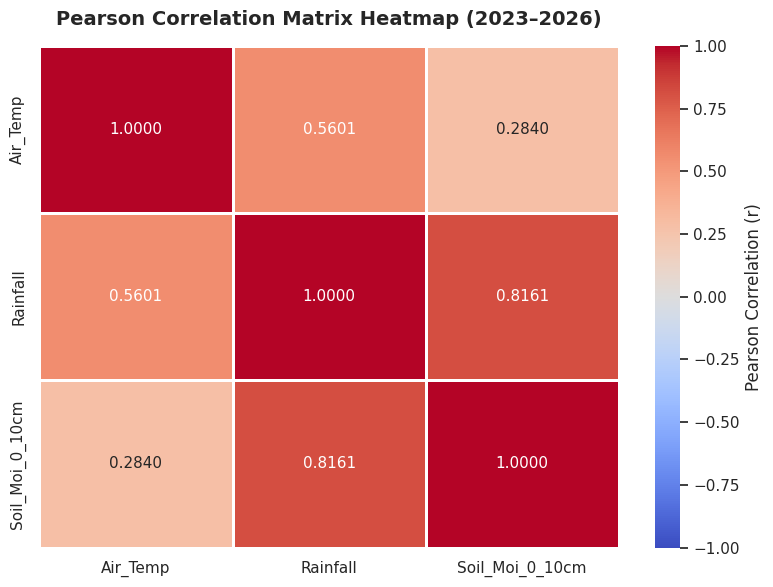

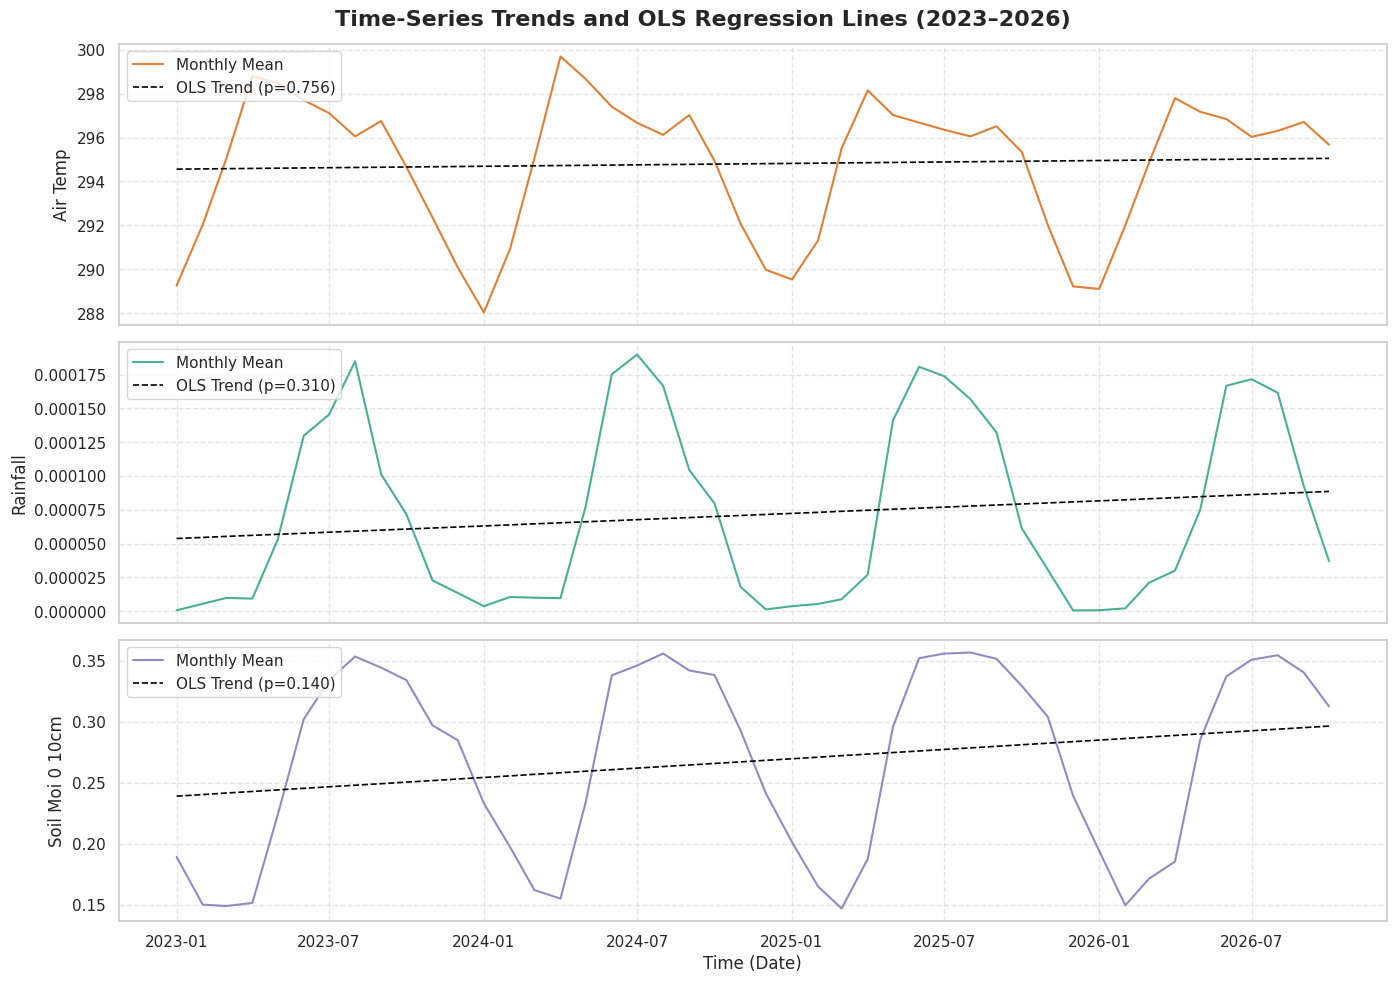

In [9]:

# Configure plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14
})

# 1. Load and prepare the 2023-2026 monthly dataset
files = sorted(glob.glob("g4.areaAvgTimeSeries.*.csv"))
dfs_monthly = []

for f in files:
    temp_df = pd.read_csv(f, skiprows=8)
    time_col = temp_df.columns[0]
    val_col = temp_df.columns[1]

    temp_df[time_col] = pd.to_datetime(temp_df[time_col], errors='coerce')
    temp_df = temp_df.dropna(subset=[time_col])
    temp_df.set_index(time_col, inplace=True)

    if 'Tair' in f:
        col_name = 'Air_Temp'
    elif 'Rainf' in f:
        col_name = 'Rainfall'
    elif 'SoilMoi00_10cm' in f:
        col_name = 'Soil_Moi_0_10cm'
    else:
        col_name = 'Value'

    monthly_series = temp_df[val_col].resample('MS').mean()
    dfs_monthly.append(monthly_series.rename(col_name))

df_merged = pd.concat(dfs_monthly, axis=1).reset_index()
df_merged = df_merged.rename(columns={df_merged.columns[0]: 'Date'})

mask = (df_merged['Date'] >= '2023-01-01') & (df_merged['Date'] <= '2026-10-30')
df_final = df_merged.loc[mask].dropna().copy()
vars_to_analyze = ['Air_Temp', 'Rainfall', 'Soil_Moi_0_10cm']

# ==========================================
# FIGURE 1: Pearson Correlation Heatmap
# ==========================================
plt.figure(figsize=(8, 6))
corr_matrix = df_final[vars_to_analyze].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".4f", linewidths=1, cbar_kws={'label': 'Pearson Correlation (r)'})
plt.title("Pearson Correlation Matrix Heatmap (2023–2026)", fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ==========================================
# FIGURE 2: Time-Series with OLS Trend Lines
# ==========================================
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
colors = ['#d95f02', '#1b9e77', '#7570b3']

for i, col in enumerate(vars_to_analyze):
    ax = axes[i]
    y = df_final[col].values
    x_num = np.arange(len(df_final))

    # Plot original monthly data
    ax.plot(df_final['Date'], y, label='Monthly Mean', color=colors[i], linewidth=1.5, alpha=0.8)

    # Compute OLS regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(x_num, y)
    trend_line = intercept + slope * x_num
    ax.plot(df_final['Date'], trend_line, color='black', linestyle='--', linewidth=1.2, label=f'OLS Trend (p={p_value:.3f})')

    ax.set_ylabel(col.replace('_', ' '))
    ax.legend(loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.5)

axes[-1].set_xlabel("Time (Date)")
fig.suptitle("Time-Series Trends and OLS Regression Lines (2023–2026)", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [10]:
# List all CSV files in the directory
csv_files = sorted(glob.glob("g4.areaAvgTimeSeries.*.csv"))

print("=" * 90)
print(f"{'CSV FILE NAME':<75} | {'ROW COUNT':<10}")
print("=" * 90)

for f in csv_files:
    # Read the CSV file skipping metadata header rows
    df = pd.read_csv(f, skiprows=8)
    print(f"{f:<75} | {len(df):<10}")

print("=" * 90)

CSV FILE NAME                                                               | ROW COUNT 
g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_Rainf_f_tavg.20230101-20261030.30E_21N_100E_56N.csv | 1399      
g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_SoilMoi00_10cm_tavg.20230101-20261030.30E_21N_100E_56N.csv | 1399      
g4.areaAvgTimeSeries.FLDAS_NOAHMP001_G_CA_D_001_Tair_f_tavg.20230101-20261030.30E_21N_100E_56N.csv | 1399      


PROJECT HEIMDALL: Model 'project-heimdall-climate-SEA'
Total Daily Records (n) = 1399
Training Samples : 912
Testing Samples  : 457


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - loss: 0.0517 - mae: 0.1706 - val_loss: 0.0084 - val_mae: 0.0821
Epoch 2/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0138 - mae: 0.0889 - val_loss: 0.0060 - val_mae: 0.0578
Epoch 3/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0105 - mae: 0.0753 - val_loss: 0.0035 - val_mae: 0.0384
Epoch 4/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0092 - mae: 0.0694 - val_loss: 0.0033 - val_mae: 0.0384
Epoch 5/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0091 - mae: 0.0696 - val_loss: 0.0036 - val_mae: 0.0415
Epoch 6/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - loss: 0.0088 - mae: 0.0675 - val_loss: 0.0027 - val_mae: 0.0329
Epoch 7/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0078 - mae: 0.0641 - val_loss: 0.0057 - val_mae: 0.0590
Epoch 8/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0077 - mae: 0.0626 - val_loss: 0.0043 - val_mae: 0.0482
Epoch 9/35
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.007

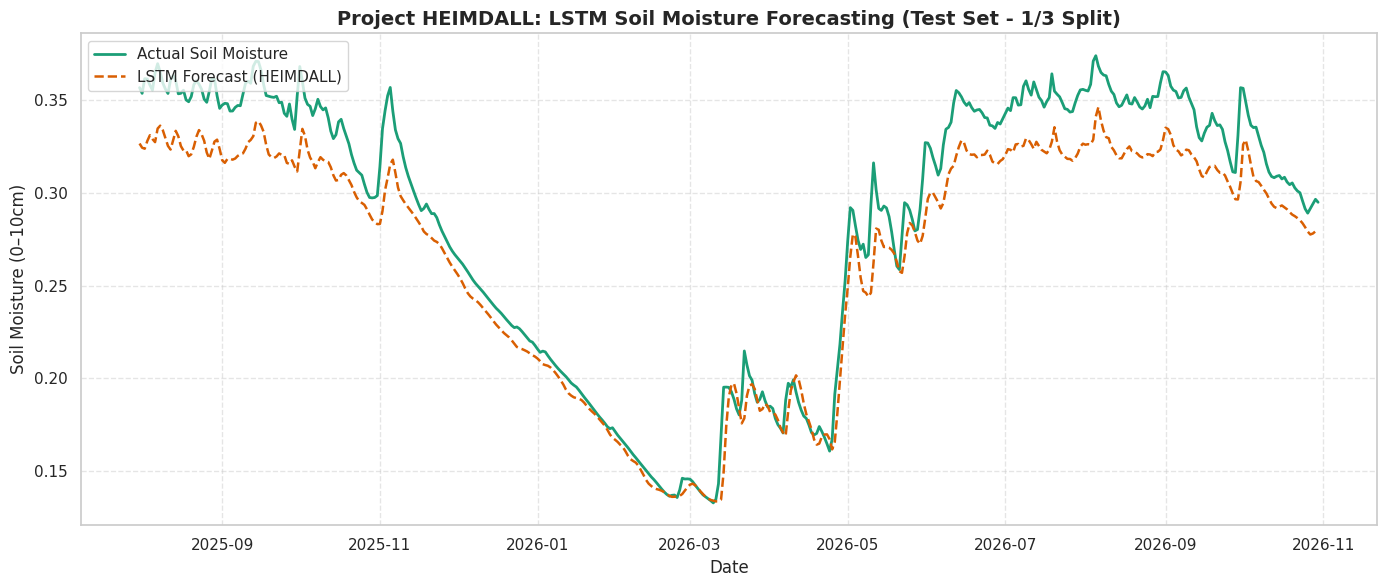

In [11]:
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Reproducibility seed
tf.random.set_seed(42)
np.random.seed(42)

# ==========================================
# 1. LOAD & PREPARE DAILY DATASET
# ==========================================
# Automatically find the daily CSV files (2023-2026 dataset)
files = sorted(glob.glob("g4.areaAvgTimeSeries.*.20230101-20261030*.csv"))
dfs = []

for f in files:
    temp_df = pd.read_csv(f, skiprows=8)
    time_col = temp_df.columns[0]
    val_col = temp_df.columns[1]

    temp_df[time_col] = pd.to_datetime(temp_df[time_col], errors='coerce')
    temp_df = temp_df.dropna(subset=[time_col])
    temp_df.set_index(time_col, inplace=True)

    if 'Tair' in f:
        col_name = 'Air_Temp'
    elif 'Rainf' in f:
        col_name = 'Rainfall'
    elif 'SoilMoi00_10cm' in f:
        col_name = 'Soil_Moi_0_10cm'
    else:
        col_name = 'Value'

    dfs.append(temp_df[val_col].rename(col_name))

# Merge into a single daily dataframe and handle missing values
df_daily = pd.concat(dfs, axis=1).dropna()
print("=" * 60)
print(f"PROJECT HEIMDALL: Model 'project-heimdall-climate-SEA'")
print(f"Total Daily Records (n) = {len(df_daily)}")
print("=" * 60)

# Features (Inputs) and Target (Soil Moisture prediction)
feature_cols = ['Air_Temp', 'Rainfall', 'Soil_Moi_0_10cm']
data = df_daily[feature_cols].values

# ==========================================
# 2. FEATURE SCALING (MinMax 0 to 1)
# ==========================================
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data)

# Helper function to create sliding temporal windows (e.g., past 30 days)
def create_sequences(dataset, target_col_idx, time_step=30):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i:(i + time_step), :])
        y.append(dataset[i + time_step, target_col_idx])
    return np.array(X), np.array(y)

TIME_STEP = 30  # Look back 30 days of climate history
target_idx = feature_cols.index('Soil_Moi_0_10cm')

X, y = create_sequences(data_scaled, target_idx, TIME_STEP)

# ==========================================
# 3. 2/3 TRAINING & 1/3 TESTING SPLIT
# ==========================================
split_index = int(len(X) * (2 / 3))

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

# ==========================================
# 4. BUILD LSTM MODEL ARCHITECTURE
# ==========================================
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)  # Predicting continuous soil moisture value
])

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])
model.summary()

# ==========================================
# 5. MODEL TRAINING
# ==========================================
history = model.fit(
    X_train, y_train,
    epochs=35,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# ==========================================
# 6. EVALUATION & INFERENCE VISUALIZATION
# ==========================================
y_pred = model.predict(X_test)

# Inverse transform to original soil moisture scale for evaluation
# Create dummy array to inverse scale properly
dummy_test_pred = np.zeros((len(y_pred), len(feature_cols)))
dummy_test_pred[:, target_idx] = y_pred.flatten()
y_pred_rescaled = scaler.inverse_transform(dummy_test_pred)[:, target_idx]

dummy_test_actual = np.zeros((len(y_test), len(feature_cols)))
dummy_test_actual[:, target_idx] = y_test.flatten()
y_test_rescaled = scaler.inverse_transform(dummy_test_actual)[:, target_idx]

# Plotting Actual vs Predicted Soil Moisture on Test Set
plt.figure(figsize=(14, 6))
test_dates = df_daily.index[TIME_STEP + split_index:]
plt.plot(test_dates, y_test_rescaled, label='Actual Soil Moisture', color='#1b9e77', linewidth=2)
plt.plot(test_dates, y_pred_rescaled, label='LSTM Forecast (HEIMDALL)', color='#d95f02', linestyle='--', linewidth=1.8)
plt.title("Project HEIMDALL: LSTM Soil Moisture Forecasting (Test Set - 1/3 Split)", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.ylabel("Soil Moisture (0–10cm)")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

PROJECT HEIMDALL: 'project-heimdall-climate-SEA' Performance Metrics
  • Root Mean Squared Error (RMSE) : 0.0217
  • Mean Absolute Error (MAE)      : 0.0183
  • R-squared (R^2 Score)          : 0.9140

[INFO] Model successfully saved as 'project-heimdall-climate-SEA.keras'!
[INFO] Scaler successfully saved as 'heimdall_scaler.save'!


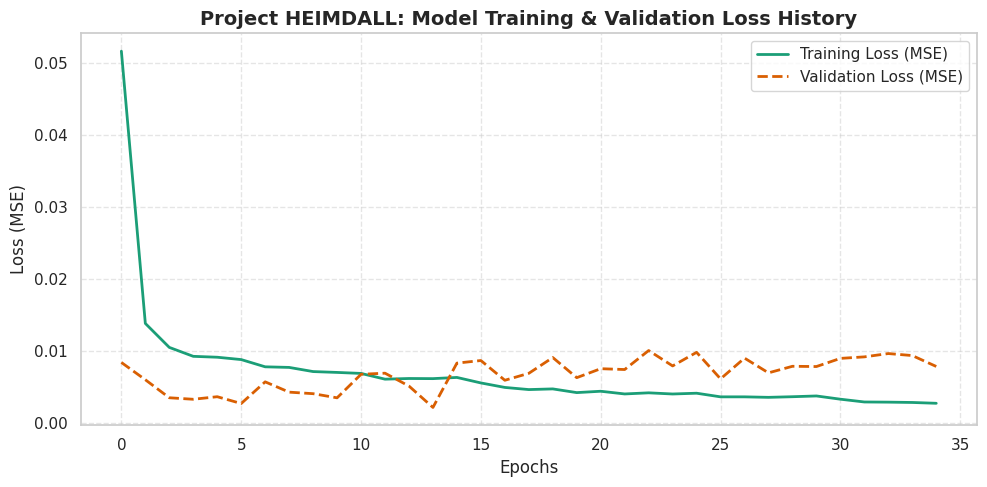

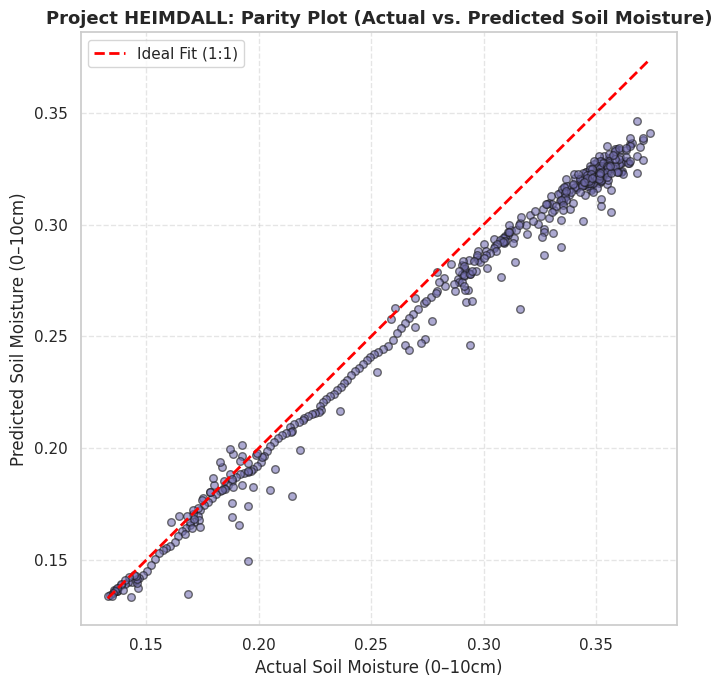

In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==========================================
# 1. COMPUTE PERFORMANCE METRICS (Fixed)
# ==========================================
rmse = np.sqrt(mean_squared_error(y_test_rescaled, y_pred_rescaled))
mae = mean_absolute_error(y_test_rescaled, y_pred_rescaled)  # Tinanggal ang extra ')' dito

r2 = r2_score(y_test_rescaled, y_pred_rescaled)

print("=" * 60)
print(f"PROJECT HEIMDALL: 'project-heimdall-climate-SEA' Performance Metrics")
print("=" * 60)
print(f"  • Root Mean Squared Error (RMSE) : {rmse:.4f}")
print(f"  • Mean Absolute Error (MAE)      : {mae:.4f}")
print(f"  • R-squared (R^2 Score)          : {r2:.4f}")
print("=" * 60)

# ==========================================
# 2. SAVE THE TRAINED MODEL & SCALER
# ==========================================
# I-save ang trained LSTM model sa disk
model.save("project-heimdall-climate-SEA.keras")
print("\n[INFO] Model successfully saved as 'project-heimdall-climate-SEA.keras'!")

# Pwede mo rin i-save ang scaler para magamit sa hinaharap kapag nag-i-inference ka
import joblib
joblib.dump(scaler, "heimdall_scaler.save")
print("[INFO] Scaler successfully saved as 'heimdall_scaler.save'!")

# ==========================================
# 3. PLOT: TRAINING & VALIDATION LOSS HISTORY
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='#1b9e77', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='#d95f02', linestyle='--', linewidth=2)
plt.title("Project HEIMDALL: Model Training & Validation Loss History", fontsize=14, fontweight='bold')
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ==========================================
# 4. PLOT: PARITY PLOT (Actual vs Predicted)
# ==========================================
plt.figure(figsize=(7, 7))
plt.scatter(y_test_rescaled, y_pred_rescaled, color='#7570b3', alpha=0.6, edgecolors='k', s=30)
min_val = min(min(y_test_rescaled), min(y_pred_rescaled))
max_val = max(max(y_test_rescaled), max(y_pred_rescaled))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (1:1)')

plt.title("Project HEIMDALL: Parity Plot (Actual vs. Predicted Soil Moisture)", fontsize=13, fontweight='bold')
plt.xlabel("Actual Soil Moisture (0–10cm)")
plt.ylabel("Predicted Soil Moisture (0–10cm)")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [16]:

print("==========================================================")
print("     PROJECT HEIMDALL: MODEL PERFORMANCE METRICS REPORT    ")
print("==========================================================")
print(f" Model Name          : project-heimdall-climate-SEA")
print(f" Target Variable     : Root-Zone Soil Moisture (0–10cm)")
print(f" Test Samples (n)    : {len(y_test_rescaled)}")
print("----------------------------------------------------------")
print(f" • Root Mean Squared Error (RMSE) : {rmse:.6f}")
print(f" • Mean Absolute Error (MAE)      : {mae:.6f}")
print(f" • R-squared (R^2) Score          : {r2:.6f}")
print("==========================================================")

if r2 >= 0.85:
    print(" Status: EXCELLENT FIT! Model captures variance remarkably well.")
elif r2 >= 0.70:
    print(" Status: GOOD FIT! Model demonstrates reliable predictive power.")
else:
    print(" Status: MODERATE FIT. Consider tuning hyperparameters.")
print("==========================================================")

     PROJECT HEIMDALL: MODEL PERFORMANCE METRICS REPORT    
 Model Name          : project-heimdall-climate-SEA
 Target Variable     : Root-Zone Soil Moisture (0–10cm)
 Test Samples (n)    : 457
----------------------------------------------------------
 • Root Mean Squared Error (RMSE) : 0.021710
 • Mean Absolute Error (MAE)      : 0.018337
 • R-squared (R^2) Score          : 0.913983
 Status: EXCELLENT FIT! Model captures variance remarkably well.


In [17]:
import statsmodels.api as sm
import pymannkendall as mk

# ==========================================
# 1. LOAD & PREPARE MONTHLY/DAILY DATA FOR STATS
# ==========================================
files = sorted(glob.glob("g4.areaAvgTimeSeries.*.20230101-20261030*.csv"))
dfs = []

for f in files:
    temp_df = pd.read_csv(f, skiprows=8)
    time_col = temp_df.columns[0]
    val_col = temp_df.columns[1]

    temp_df[time_col] = pd.to_datetime(temp_df[time_col], errors='coerce')
    temp_df = temp_df.dropna(subset=[time_col])
    temp_df.set_index(time_col, inplace=True)

    if 'Tair' in f:
        col_name = 'Air_Temp'
    elif 'Rainf' in f:
        col_name = 'Rainfall'
    elif 'SoilMoi00_10cm' in f:
        col_name = 'Soil_Moi_0_10cm'
    else:
        col_name = 'Value'

    dfs.append(temp_df[val_col].rename(col_name))

df_all = pd.concat(dfs, axis=1).dropna()

# Resample to monthly means for macro trend & significance testing
df_monthly = df_all.resample('ME').mean()

print("=" * 70)
print("     PROJECT HEIMDALL: STATISTICAL SIGNIFICANCE REPORT     ")
print("=" * 70)
print(f" Total Aligned Months (n) = {len(df_monthly)}")
print("-" * 70)

# ==========================================
# 2. PEARSON CORRELATION MATRIX (p-values)
# ==========================================
print("\n[1] PEARSON CORRELATION & P-VALUES:")
cols = df_monthly.columns
corr_matrix = pd.DataFrame(index=cols, columns=cols)
pval_matrix = pd.DataFrame(index=cols, columns=cols)

for c1 in cols:
    for c2 in cols:
        r, p = stats.pearsonr(df_monthly[c1], df_monthly[c2])
        corr_matrix.loc[c1, c2] = f"{r:.4f}"
        pval_matrix.loc[c1, c2] = f"{p:.4e}"

print("Correlation Coefficients (r):")
print(corr_matrix)
print("\nCorresponding p-values:")
print(pval_matrix)

# ==========================================
# 3. OLS REGRESSION (Rate of Change & p-value)
# ==========================================
print("\n" + "=" * 70)
print("[2] OLS REGRESSION (Parametric Rate of Change & Significance):")
print("-" * 70)

X_time = np.arange(len(df_monthly))
X_time_sm = sm.add_constant(X_time)

for col in cols:
    y = df_monthly[col].values
    ols_model = sm.OLS(y, X_time_sm).fit()
    slope = ols_model.params[1]
    p_val = ols_model.pvalues[1]
    r_squared = ols_model.rsquared

    print(f" • Variable: {col}")
    print(f"   - Monthly Rate of Change (Slope): {slope:.6f}")
    print(f"   - R-squared (R^2)              : {r_squared:.4f}")
    print(f"   - p-value                      : {p_val:.4e} {'(Significant)' if p_val < 0.05 else '(Not Significant / Stable)'}")

# ==========================================
# 4. MANN-KENDALL TREND TEST (Non-Parametric)
# ==========================================
print("\n" + "=" * 70)
print("[3] MANN-KENDALL TREND TEST (Non-Parametric Monotonic Trend):")
print("-" * 70)

for col in cols:
    mk_result = mk.original_test(df_monthly[col].values)
    print(f" • Variable: {col}")
    print(f"   - Trend                         : {mk_result.trend}")
    print(f"   - Z-statistic                   : {mk_result.z:.4f}")
    print(f"   - p-value                       : {mk_result.p:.4e}")
    print(f"   - Sen's Slope (Rate of Change)  : {mk_result.slope:.6f}")

print("=" * 70)
print("Statistical significance analysis completed successfully!")
print("=" * 70)

     PROJECT HEIMDALL: STATISTICAL SIGNIFICANCE REPORT     
 Total Aligned Months (n) = 46
----------------------------------------------------------------------

[1] PEARSON CORRELATION & P-VALUES:
Correlation Coefficients (r):
                Rainfall Soil_Moi_0_10cm Air_Temp
Rainfall          1.0000          0.8161   0.5601
Soil_Moi_0_10cm   0.8161          1.0000   0.2840
Air_Temp          0.5601          0.2840   1.0000

Corresponding p-values:
                   Rainfall Soil_Moi_0_10cm    Air_Temp
Rainfall         0.0000e+00      4.8173e-12  5.1708e-05
Soil_Moi_0_10cm  4.8173e-12      0.0000e+00  5.5795e-02
Air_Temp         5.1708e-05      5.5795e-02  0.0000e+00

[2] OLS REGRESSION (Parametric Rate of Change & Significance):
----------------------------------------------------------------------
 • Variable: Rainfall
   - Monthly Rate of Change (Slope): 0.000001
   - R-squared (R^2)              : 0.0234
   - p-value                      : 3.1030e-01 (Not Significant / Stable)
 •